# ToysAD-8K DS2 Fixed Pipeline Inference

**Notebook file:** `08b-toysad8k-ds2-frozen-pipeline.ipynb`

This notebook runs the fixed model-facing confirmation path on 300 untouched development scenes and all 6,000 views. SAM 2.1 receives the supplied reference boxes, then DINOv2-small extracts the frozen object representation and calculates B0 and P1.

The same images also follow the proposed automatic route. The DS1-selected LocateAnything model, prompt, and post-processing rule generate boxes, SAM 2.1 converts those boxes into masks, and DINOv2-small calculates B0 and P1. Supplied masks remain the scientific upper bound. Reference boxes represent a user-confirmed assisted route.

Before evaluator labels are opened, this run applies a predeclared bounded DS2 operational policy. LocateAnything is limited to 4,096 new tokens, two attempts, and 75 seconds per attempt. A terminal generation failure is recorded and carried forward as zero proposals, so it becomes an end-to-end miss instead of stopping the full experiment. This changes the runtime policy, not the selected model, prompt, or box post-processing rule.

On Kaggle, this notebook requires the real pinned models. A local contract mode is available only to test paths, schemas, restart behaviour, tables, and figures. Contract values are not model evidence and must not be used in the progress report.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08B DS2 frozen pipeline`  
Clean notebook SHA-256: `8277ce5de28773b6004a7dfbf8671d27bf80729f8608c97ab97800286cdf693d`  
Downloaded saved-output SHA-256: `25e16e0108b23b78267f84e8eba5de5e1b2c79a8f59025aa48921cf87dbb176f`


## Questions answered by this run

1. Does the fixed LocateAnything choice produce usable proposals across all 6,000 images under the bounded runtime policy?
2. Does SAM 2.1 complete the reference-box and automatic-box routes with stable masks?
3. Does the frozen DINOv2-small B0 and P1 path complete all three routes without opening labels?
4. How many proposal generations or masks are unusable, and are the real proposal panels, mask overlays, and coarse P1 heatmaps visually reasonable?

Accuracy, ranking quality, view fusion, and the DS2 confirmation status are measured only in Notebook 08C.

In [1]:
from __future__ import annotations

import importlib.metadata
from hashlib import sha256
import json
import os
from pathlib import Path
import shutil
import subprocess
import sys
import time
import zipfile

sys.dont_write_bytecode = True

from IPython.display import Image as NotebookImage, display

NOTEBOOK_NAME = "08b-toysad8k-ds2-frozen-pipeline.ipynb"
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/input").is_dir() else "local"
RUN_MODE = os.getenv(
    "VPI_RUN_MODE",
    "model_inference" if EXECUTION_ENVIRONMENT == "kaggle" else "contract",
)
if RUN_MODE not in {"contract", "model_inference"}:
    raise ValueError("VPI_RUN_MODE must be contract or model_inference")
if EXECUTION_ENVIRONMENT == "kaggle" and RUN_MODE != "model_inference":
    raise RuntimeError("Kaggle evidence must use the real pinned models")
OUTPUT_ROOT = Path(os.getenv(
    "VPI_OUTPUT_ROOT",
    "/kaggle/temp/toysad8k_ds2_frozen_pipeline" if EXECUTION_ENVIRONMENT == "kaggle" else ".local/runs/toysad8k-ds2-frozen-pipeline",
)).expanduser().resolve()
RECOVERY_OUTPUT_ROOT = (
    Path("/kaggle/working/notebook08b_recovery").resolve()
    if EXECUTION_ENVIRONMENT == "kaggle"
    else OUTPUT_ROOT.parent / "notebook08b_recovery"
)

In [2]:
def kaggle_dataset_roots() -> list[Path]:
    input_root = Path("/kaggle/input")
    if not input_root.is_dir():
        return []
    candidates: list[Path] = []
    for pattern in (
        "*",
        "datasets/*/*",
        "datasets/*/*/versions/*",
        "notebooks/*/*",
        "notebooks/*/*/versions/*",
    ):
        candidates.extend(path for path in input_root.glob(pattern) if path.is_dir())
    return sorted(set(candidates), key=lambda path: path.as_posix())


def find_code_root() -> Path:
    configured = os.getenv("VPI_CODE_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    candidates.extend((Path.cwd(), *Path.cwd().parents))
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for mounted in kaggle_dataset_roots():
            candidates.extend((mounted, mounted / "code"))
    for candidate in candidates:
        if (candidate / "src/visual_peer_inspector/data/cohort_contract.py").is_file():
            return candidate.resolve()
    mounted_names = sorted(path.name for path in input_root.iterdir()) if input_root.is_dir() else []
    raise FileNotFoundError(
        f"Could not locate the Visual Peer Inspector code snapshot. Mounted inputs: {mounted_names}"
    )


def find_package(package_kind: str, variable: str) -> Path:
    configured = os.getenv(variable)
    candidates = [Path(configured).expanduser()] if configured else []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for mounted in kaggle_dataset_roots():
            candidates.append(mounted)
            candidates.extend(
                child for child in sorted(mounted.iterdir()) if child.is_dir()
            )
    for candidate in candidates:
        record_path = candidate / "package_record.json"
        if not record_path.is_file():
            continue
        try:
            record = json.loads(record_path.read_text(encoding="utf-8"))
        except Exception:
            continue
        is_rgb_package = (
            package_kind == "toysad8k-model-input"
            and record.get("cohort_id") == "toysad8k-development-confirm-300-v1"
            and (candidate / "neutral_corpus_manifest.jsonl").is_file()
            and (candidate / "media").is_dir()
        )
        if record.get("package_kind") == package_kind or is_rgb_package:
            return candidate.resolve()
    raise FileNotFoundError(f"Could not locate package kind: {package_kind}")


def find_named_input_file(name: str, variable: str) -> Path:
    configured = os.getenv(variable)
    if configured:
        path = Path(configured).expanduser()
        if path.is_file():
            return path.resolve()
    patterns = (
        name,
        f"*/{name}",
        f"*/*/{name}",
        f"*/*/*/{name}",
        f"*/*/*/*/{name}",
    )
    matches = []
    for mounted in kaggle_dataset_roots():
        for pattern in patterns:
            matches.extend(path for path in mounted.glob(pattern) if path.is_file())
    unique = sorted(set(matches), key=lambda path: path.as_posix())
    if not unique:
        raise FileNotFoundError(f"Could not find mounted input file: {name}")
    digests = {sha256(path.read_bytes()).hexdigest() for path in unique}
    if len(digests) != 1:
        raise ValueError(f"Mounted copies of {name} do not match")
    preferred = sorted(
        unique,
        key=lambda path: ("downstream" not in path.parts, path.as_posix()),
    )
    return preferred[0].resolve()


def read_secret(name: str) -> str | None:
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.getenv(name)


def code_environment() -> dict[str, str]:
    environment = os.environ.copy()
    source_root = str(CODE_ROOT / "src")
    previous = environment.get("PYTHONPATH")
    environment["PYTHONPATH"] = source_root if not previous else source_root + os.pathsep + previous
    return environment


def run_clearml_finalizer(safe_root: Path, stage: str, task_name: str, tags: list[str], receipt: Path) -> dict:
    mode = "online" if EXECUTION_ENVIRONMENT == "kaggle" else "disabled"
    environment = code_environment()
    if mode == "online":
        access = read_secret("CLEARML_API_ACCESS_KEY")
        secret = read_secret("CLEARML_API_SECRET_KEY")
        if not access or not secret:
            mode = "disabled"
        else:
            environment.update({
                "CLEARML_API_ACCESS_KEY": access,
                "CLEARML_API_SECRET_KEY": secret,
                "CLEARML_API_HOST": "https://api.clear.ml",
                "CLEARML_WEB_HOST": "https://app.clear.ml",
                "CLEARML_FILES_HOST": "https://files.clear.ml",
            })
    command = [
        sys.executable,
        str(CODE_ROOT / "scripts/finalize_ds2_clearml.py"),
        "--safe-root", str(safe_root),
        "--receipt", str(receipt),
        "--stage", stage,
        "--task-name", task_name,
        "--mode", mode,
    ]
    for tag in tags:
        command.extend(("--tag", tag))
    try:
        subprocess.run(command, env=environment, check=True, timeout=240)
    except Exception as error:
        receipt.parent.mkdir(parents=True, exist_ok=True)
        receipt.write_text(json.dumps({
            "schema_version": 1,
            "status": "failed",
            "error_type": type(error).__name__,
            "task_id": None,
        }, indent=2) + "\\n", encoding="utf-8")
    return json.loads(receipt.read_text(encoding="utf-8"))

## Locate and verify the model-safe inputs

In [3]:
CODE_ROOT = find_code_root()
sys.path.insert(0, str(CODE_ROOT / "src"))
RGB_ROOT = find_package("toysad8k-model-input", "VPI_RGB_ROOT")
GEOMETRY_ROOT = find_package("ds2-oracle-geometry", "VPI_GEOMETRY_ROOT")


def locate_selected_prompt() -> Path:
    configured = os.getenv("VPI_SELECTED_PROMPT")
    if configured:
        path = Path(configured).expanduser()
        if path.is_file():
            return path.resolve()
    # Kaggle mounts the completed Notebook 04.3 archive as a notebook input.
    archive_path = find_named_input_file(
        "ds1-locateanything-prompt-freeze-downstream-input.zip",
        "VPI_SELECTED_PROMPT_ARCHIVE",
    )
    verification_path = find_named_input_file(
        "ds1-locateanything-prompt-freeze-verification.json",
        "VPI_SELECTED_PROMPT_VERIFICATION",
    )
    verification = json.loads(verification_path.read_text(encoding="utf-8"))
    matches = [row for row in verification["archives"] if row["path"] == archive_path.name]
    actual_sha256 = sha256(archive_path.read_bytes()).hexdigest()
    if len(matches) != 1 or matches[0]["sha256"] != actual_sha256:
        raise ValueError("The DS1 prompt archive differs from its producer record")
    checksums_path = verification_path.parent / "SHA256SUMS"
    if not checksums_path.is_file():
        raise FileNotFoundError("The DS1 prompt checksum manifest is missing")
    checksums = {
        line.split(maxsplit=1)[1].strip(): line.split(maxsplit=1)[0]
        for line in checksums_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    }
    if checksums.get(archive_path.name) != actual_sha256:
        raise ValueError("The DS1 prompt archive differs from SHA256SUMS")
    destination = Path("/kaggle/temp/ds1_prompt_freeze_input").resolve()
    marker = destination / "downstream/selected_prompt.json"
    if not marker.is_file():
        with zipfile.ZipFile(archive_path) as archive:
            if archive.testzip() is not None:
                raise ValueError("The DS1 prompt archive failed its integrity check")
            for name in archive.namelist():
                member = Path(name)
                if member.is_absolute() or ".." in member.parts:
                    raise ValueError(f"Unsafe prompt archive member: {name}")
            archive.extractall(destination)
    if not marker.is_file():
        raise FileNotFoundError("The DS1 prompt archive does not contain selected_prompt.json")
    return marker


SELECTED_PROMPT = locate_selected_prompt()


def locate_recovery_input() -> Path | None:
    configured = os.getenv("VPI_RECOVERY_INPUT_ROOT")
    if configured:
        root = Path(configured).expanduser().resolve()
        if not (
            (root / "recovery_snapshot.zip").is_file()
            or (root / "recovery_record.json").is_file()
        ):
            raise FileNotFoundError("Configured DS2 recovery input is invalid")
        return root
    if EXECUTION_ENVIRONMENT != "kaggle":
        return None
    input_root = Path("/kaggle/input")
    snapshot_roots = {
        path.parent.resolve()
        for path in input_root.glob("**/recovery_snapshot.zip")
        if path.is_file()
    }
    legacy_roots = {
        path.parent.resolve()
        for path in input_root.glob("**/recovery_record.json")
        if path.is_file()
    }
    candidates = sorted(snapshot_roots or legacy_roots, key=lambda path: path.as_posix())
    if len(candidates) > 1:
        raise ValueError("Multiple DS2 recovery inputs were found")
    return candidates[0] if candidates else None


RECOVERY_INPUT_ROOT = locate_recovery_input()

from visual_peer_inspector.data.cohort_contract import DS2_CONFIRM_CONTRACT
from visual_peer_inspector.data.model_safe_package import verify_model_input_package
from visual_peer_inspector.evaluation.confirmation_reference import verify_ds2_geometry_package
from visual_peer_inspector.workflows.locateanything_confirmation_ds2 import (
    DS2_ATTEMPT_TIMEOUT_SECONDS,
    DS2_MAXIMUM_ATTEMPTS_PER_JOB,
    DS2_MAX_NEW_TOKENS,
    DS2_TERMINAL_FAILURE_DISPOSITION,
)

rgb_audit = verify_model_input_package(RGB_ROOT, contract=DS2_CONFIRM_CONTRACT)
geometry_record = verify_ds2_geometry_package(GEOMETRY_ROOT)
selected_prompt_record = json.loads(SELECTED_PROMPT.read_text(encoding="utf-8"))
if (
    selected_prompt_record.get("stage") != "ds1_locateanything_prompt_freeze"
    or selected_prompt_record.get("development_only") is not True
    or selected_prompt_record.get("requires_unchanged_ds2_confirmation") is not True
):
    raise ValueError("The mounted LocateAnything decision is not a frozen DS1 selection")
display({
    "cohort": DS2_CONFIRM_CONTRACT.cohort_id,
    "scenes": rgb_audit.scene_count,
    "images": rgb_audit.image_count,
    "visible object prompts": geometry_record["visible_object_view_count"],
    "LocateAnything prompt": selected_prompt_record["selected"]["prompt"],
    "proposal post-processing": selected_prompt_record["selected"]["postprocessing_policy"],
    "maximum new tokens": DS2_MAX_NEW_TOKENS,
    "maximum attempts per image": DS2_MAXIMUM_ATTEMPTS_PER_JOB,
    "attempt timeout seconds": DS2_ATTEMPT_TIMEOUT_SECONDS,
    "terminal failure handling": DS2_TERMINAL_FAILURE_DISPOSITION,
    "recovery input": RECOVERY_INPUT_ROOT is not None,
    "labels mounted": False,
})

{'cohort': 'toysad8k-development-confirm-300-v1',
 'scenes': 300,
 'images': 6000,
 'visible object prompts': 23100,
 'LocateAnything prompt': 'individual object',
 'proposal post-processing': 'area_nms_075_cap8',
 'maximum new tokens': 4096,
 'maximum attempts per image': 2,
 'attempt timeout seconds': 75.0,
 'terminal failure handling': 'carry_as_zero_proposal',
 'recovery input': False,
 'labels mounted': False}

## Prepare the pinned GPU runtime

In [4]:
checkpoint_path = None
runtime_evidence = {
    "execution environment": EXECUTION_ENVIRONMENT,
    "run mode": RUN_MODE,
    "LocateAnything model": "nvidia/LocateAnything-3B",
    "LocateAnything revision": "c32291ca5e996f5a7a485845b4f57a233936bba0",
    "DINO model": "facebook/dinov2-small",
    "DINO revision": "ed25f3a31f01632728cabb09d1542f84ab7b0056",
}
if RUN_MODE == "model_inference":
    install_environment = code_environment()
    install_environment["SAM2_BUILD_CUDA"] = "0"

    # Install only the add-ons that are absent from the Kaggle image.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_ROOT / "requirements/confirmation-lock.txt")], check=True, timeout=900, env=install_environment)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q", "--no-deps",
        "git+https://github.com/facebookresearch/sam2.git@2b90b9f5ceec907a1c18123530e92e794ad901a4",
    ], check=True, timeout=600, env=install_environment)

    import torch
    from huggingface_hub import hf_hub_download
    from visual_peer_inspector.data.model_safe_package import file_sha256
    from visual_peer_inspector.models.sam2 import Sam2Configuration

    if not torch.cuda.is_available():
        raise RuntimeError("Notebook 08B requires a Kaggle GPU")
    configuration = Sam2Configuration()
    checkpoint_path = Path(hf_hub_download(
        repo_id=configuration.model_repository,
        filename=configuration.checkpoint_filename,
        revision=configuration.model_revision,
        cache_dir="/tmp/vpi-sam21-model-cache",
    ))
    if checkpoint_path.stat().st_size != configuration.checkpoint_size_bytes or file_sha256(checkpoint_path) != configuration.checkpoint_sha256:
        raise RuntimeError("The pinned SAM 2.1 checkpoint identity differs")
    runtime_evidence.update({
        "GPU": torch.cuda.get_device_name(0),
        "GPU count": torch.cuda.device_count(),
        "SAM checkpoint SHA-256": configuration.checkpoint_sha256,
    })
else:
    runtime_evidence["evidence boundary"] = "Local contract validation only"
display(runtime_evidence)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.4 MB/s eta 0:00:00


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.4/299.4 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 92.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 8.6 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


sam2.1_hiera_large.pt:   0%|          | 0.00/898M [00:00<?, ?B/s]

{'execution environment': 'kaggle',
 'run mode': 'model_inference',
 'LocateAnything model': 'nvidia/LocateAnything-3B',
 'LocateAnything revision': 'c32291ca5e996f5a7a485845b4f57a233936bba0',
 'DINO model': 'facebook/dinov2-small',
 'DINO revision': 'ed25f3a31f01632728cabb09d1542f84ab7b0056',
 'GPU': 'Tesla T4',
 'GPU count': 2,
 'SAM checkpoint SHA-256': '2647878d5dfa5098f2f8649825738a9345572bae2d4350a2468587ece47dd318'}

## Run the fixed model-facing pipeline

The models run sequentially on one GPU. LocateAnything is released before SAM 2.1 loads, and SAM is released before DINOv2-small loads. The one-image and 20-image stages must pass operational and integrity checks before the 6,000-image run starts. Agreement values are reported, not used as a quality cutoff. The pipeline prints progress after the first image and at fixed intervals. Results are written atomically so an identical rerun can resume from verified checkpoints. Invalid proposal generations and masks remain explicit evidence and do not disappear from the downstream coverage.

ClearML is not active during model loading or inference.

In [5]:
command = [
    sys.executable,
    str(CODE_ROOT / "scripts/run_ds2_inference.py"),
    "--rgb-root", str(RGB_ROOT),
    "--geometry-root", str(GEOMETRY_ROOT),
    "--selected-prompt", str(SELECTED_PROMPT),
    "--output-root", str(OUTPUT_ROOT),
    "--run-mode", RUN_MODE,
    "--device", "cuda" if RUN_MODE == "model_inference" else "cpu",
    "--batch-size", "32",
    "--recovery-output-root", str(RECOVERY_OUTPUT_ROOT),
]
if RECOVERY_INPUT_ROOT is not None:
    command.extend(("--recovery-input-root", str(RECOVERY_INPUT_ROOT)))
if checkpoint_path is not None:
    command.extend(("--sam-checkpoint", str(checkpoint_path)))
subprocess.run(command, check=True, env=code_environment())

proposal_record = json.loads((OUTPUT_ROOT / "locateanything/safe/run_record.json").read_text(encoding="utf-8"))
reference_sam_record = json.loads((OUTPUT_ROOT / "sam21/reference-box/safe/run_record.json").read_text(encoding="utf-8"))
automatic_sam_record = json.loads((OUTPUT_ROOT / "sam21/automatic-box/safe/run_record.json").read_text(encoding="utf-8"))
representation_record = json.loads((OUTPUT_ROOT / "representation/safe/run_record.json").read_text(encoding="utf-8"))
display({
    "run mode": RUN_MODE,
    "LocateAnything status": proposal_record["status"],
    "proposal images": proposal_record["image_count"],
    "proposal generation failures": proposal_record["terminal_failed_image_count"],
    "discarded untrusted boxes": proposal_record["discarded_untrusted_box_count"],
    "zero-proposal images": proposal_record["zero_proposal_image_count"],
    "LocateAnything policy SHA-256": proposal_record["effective_operational_policy_sha256"],
    "reference-box SAM status": reference_sam_record["status"],
    "automatic-box SAM status": automatic_sam_record["status"],
    "SAM images per route": reference_sam_record["image_count"],
    "DINO status": representation_record["status"],
    "score rows": representation_record["score_row_count"],
    "unscoreable score rows": representation_record["unscoreable_row_count"],
    "invalid-mask score rows": representation_record["invalid_mask_row_count"],
    "evaluator opened": representation_record["evaluator_opened"],
})

{"component": "LocateAnything", "device": "cuda", "dtype": "torch.float16", "stage": "dependencies_ready"}
{"component": "LocateAnything", "source_kind": "hub", "stage": "tokenizer_load_started"}
{"component": "LocateAnything", "stage": "tokenizer_ready"}
{"component": "LocateAnything", "source_kind": "hub", "stage": "processor_load_started"}


/usr/local/lib/python3.12/dist-packages/transformers/models/auto/image_processing_auto.py:647: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(


{"component": "LocateAnything", "stage": "processor_ready"}
{"component": "LocateAnything", "source_kind": "hub", "stage": "model_weights_load_started"}


`torch_dtype` is deprecated! Use `dtype` instead!
Fetching 2 files: 100%|██████████| 2/2 [00:30<00:00, 15.10s/it]
Qwen2ForCausalLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly defined. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with an auto class. See https://huggingface.co/docs/transformers/en/model_doc/auto#auto-classes
  - If you are the owner of the model architecture code, please modify your model class such that it inherits from `GenerationMixin` (after `PreTrainedModel`, otherwise you'll get an exception).
  - If you are not the owner of the model architecture class, please contact the model code owner to update it.
Loading checkpoint shards: 100%|██████████| 2/2 [00:0

{"component": "LocateAnything", "stage": "model_weights_loaded"}
{"component": "LocateAnything", "device": "cuda", "stage": "model_device_move_started"}
{"component": "LocateAnything", "device": "cuda", "stage": "model_ready"}


/root/.cache/huggingface/modules/transformers_modules/nvidia/LocateAnything_hyphen_3B/c32291ca5e996f5a7a485845b4f57a233936bba0/generate_utils.py:186: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  box_avg.append(torch.tensor(out_ref, dtype=x0.dtype, device=x0.device))


DS2 LocateAnything images: 1/6000
DS2 LocateAnything images: 250/6000
DS2 LocateAnything images: 500/6000
DS2 LocateAnything images: 750/6000
DS2 LocateAnything images: 1000/6000
Saved DS2 recovery files: 1
DS2 LocateAnything images: 1250/6000
DS2 LocateAnything images: 1500/6000
DS2 LocateAnything images: 1750/6000
DS2 LocateAnything images: 2000/6000
Saved DS2 recovery files: 1
DS2 LocateAnything images: 2250/6000
DS2 LocateAnything images: 2500/6000
DS2 LocateAnything images: 2750/6000
DS2 LocateAnything images: 3000/6000
Saved DS2 recovery files: 1
DS2 LocateAnything images: 3250/6000
DS2 LocateAnything images: 3500/6000
DS2 LocateAnything images: 3750/6000
DS2 LocateAnything images: 4000/6000
Saved DS2 recovery files: 1
DS2 LocateAnything images: 4250/6000
DS2 LocateAnything images: 4500/6000
DS2 LocateAnything images: 4750/6000
DS2 LocateAnything images: 5000/6000
Saved DS2 recovery files: 1
DS2 LocateAnything images: 5250/6000
DS2 LocateAnything images: 5500/6000
DS2 LocateAnyth

/usr/local/lib/python3.12/dist-packages/torchvision/transforms/functional.py:154: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  img = torch.from_numpy(pic.transpose((2, 0, 1))).contiguous()


DS2 SAM images: 1/6000
DS2 SAM images: 250/6000
DS2 SAM images: 500/6000
DS2 SAM images: 750/6000
DS2 SAM images: 1000/6000
Saved DS2 recovery files: 1001
DS2 SAM images: 1250/6000
DS2 SAM images: 1500/6000
DS2 SAM images: 1750/6000
DS2 SAM images: 2000/6000
Saved DS2 recovery files: 2001
DS2 SAM images: 2250/6000
DS2 SAM images: 2500/6000
DS2 SAM images: 2750/6000
DS2 SAM images: 3000/6000
Saved DS2 recovery files: 3001
DS2 SAM images: 3250/6000
DS2 SAM images: 3500/6000
DS2 SAM images: 3750/6000
DS2 SAM images: 4000/6000
Saved DS2 recovery files: 4001
DS2 SAM images: 4250/6000
DS2 SAM images: 4500/6000
DS2 SAM images: 4750/6000
DS2 SAM images: 5000/6000
Saved DS2 recovery files: 5001
DS2 SAM images: 5250/6000
DS2 SAM images: 5500/6000
DS2 SAM images: 5750/6000
DS2 SAM images: 6000/6000
Saved DS2 recovery files: 6001
Saved DS2 recovery files: 6001
DS2 automatic-box SAM images: 1/5962
DS2 automatic-box SAM images: 250/5962
DS2 automatic-box SAM images: 500/5962
DS2 automatic-box SAM im

{'run mode': 'model_inference',
 'LocateAnything status': 'completed',
 'proposal images': 6000,
 'proposal generation failures': 2,
 'discarded untrusted boxes': 227,
 'zero-proposal images': 38,
 'LocateAnything policy SHA-256': 'bd94b9a8182bd92e17b4ca273adc05bec6415aff18ef4f8f486c4c39161ce06d',
 'reference-box SAM status': 'completed',
 'automatic-box SAM status': 'completed',
 'SAM images per route': 6000,
 'DINO status': 'completed',
 'score rows': 138760,
 'unscoreable score rows': 530,
 'invalid-mask score rows': 2,
 'evaluator opened': False}

## Operational tables and report-ready charts

,check,passed
0,all DS2 images completed,True
1,all terminal failures carried as zero proposals,True
2,"DS1 prompt, model and post-processing kept",True
3,bounded DS2 operational policy recorded,True
4,evaluator remained closed,True


,attempt_timeout_seconds,configuration_sha256,discarded_untrusted_box_count,effective_max_new_tokens,effective_operational_policy_sha256,failed_job_count,failure_type_counts,images_per_second,job_count,maximum_attempts_per_job,...,p95_runtime_seconds,possibly_truncated_count,scene_count,successful_job_count,terminal_failure_disposition,terminal_row_count,terminal_zero_proposal_image_count,total_runtime_seconds,truncation_check_counts,zero_proposal_image_count
0,75.0,6167320c6cc3c7233385494b3e54f793eb4acaa6f21d8a...,227,4096,bd94b9a8182bd92e17b4ca273adc05bec6415aff18ef4f...,2,{'PossibleTruncation': 2},1.800572,6000,2,...,0.693,2,300,5998,carry_as_zero_proposal,6000,0,3332.2751,{'token_count_heuristic': 6000},0


,box_agreement_rate,job_count,matching_job_count
0,1.0,20,20


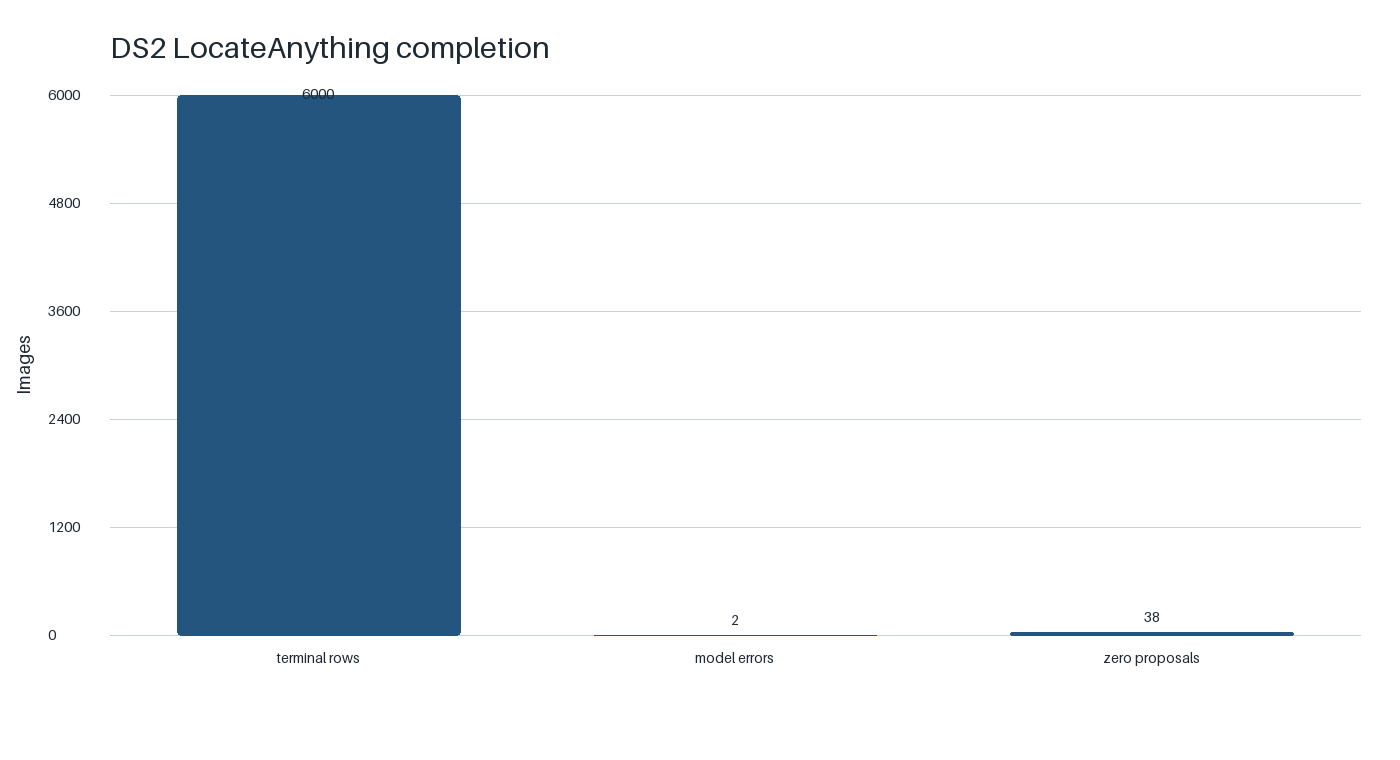

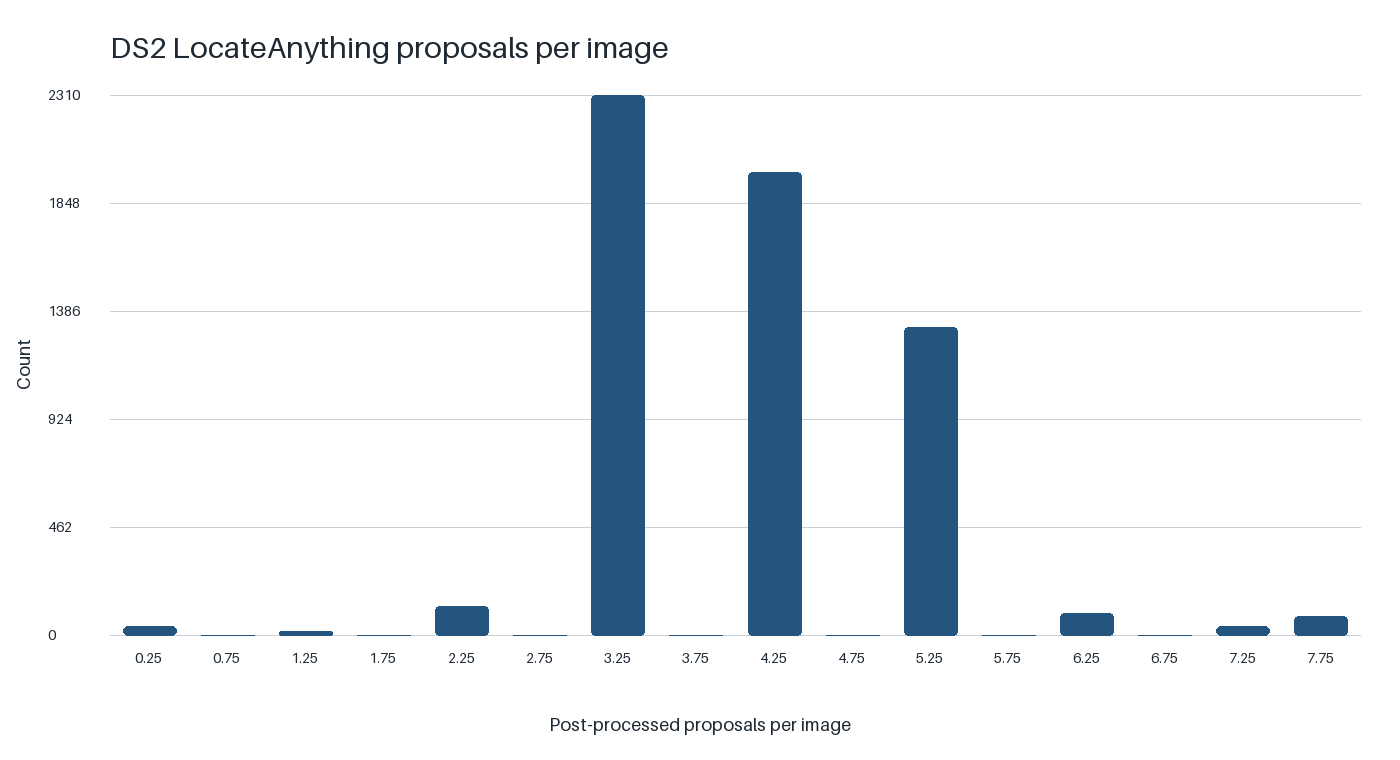

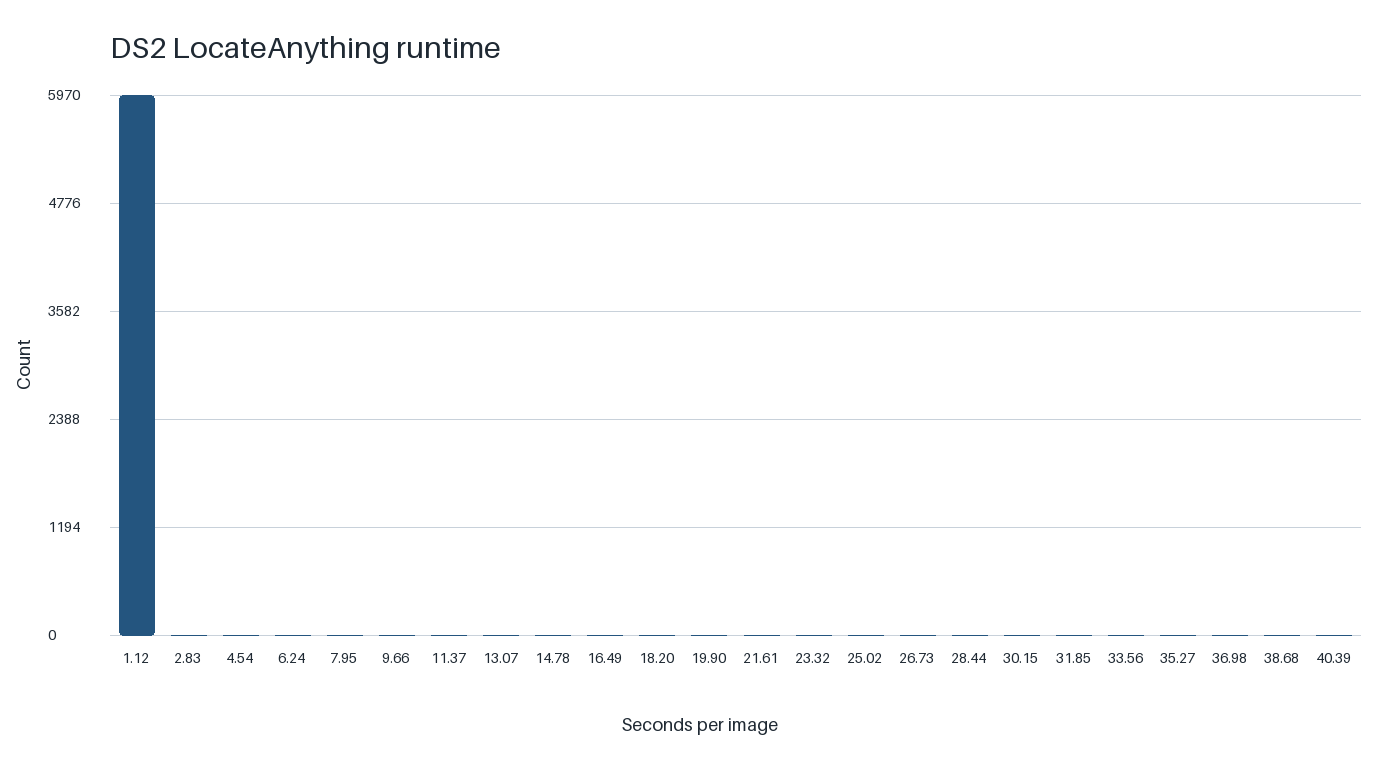

SAM route: reference-box


,check,passed
0,all DS2 images recorded,True
1,stored prompts match the frozen input,True
2,pilot repeat completed and was measured,True
3,no unresolved SAM image failures,True


,route,image_count,mask_count,zero_prompt_image_count,empty_mask_count,mean_predicted_quality_score,median_runtime_seconds,p95_runtime_seconds
0,reference_box,6000,23100,0,0,0.978649,0.268637,0.274002


,mask_digest_agreement_rate,matching_mask_digest_count,matching_score_count,pilot_image_count,prompt_count,repeat_image_count,score_agreement_rate,score_tolerance
0,1.0,81,81,20,81,20,1.0,0.00001


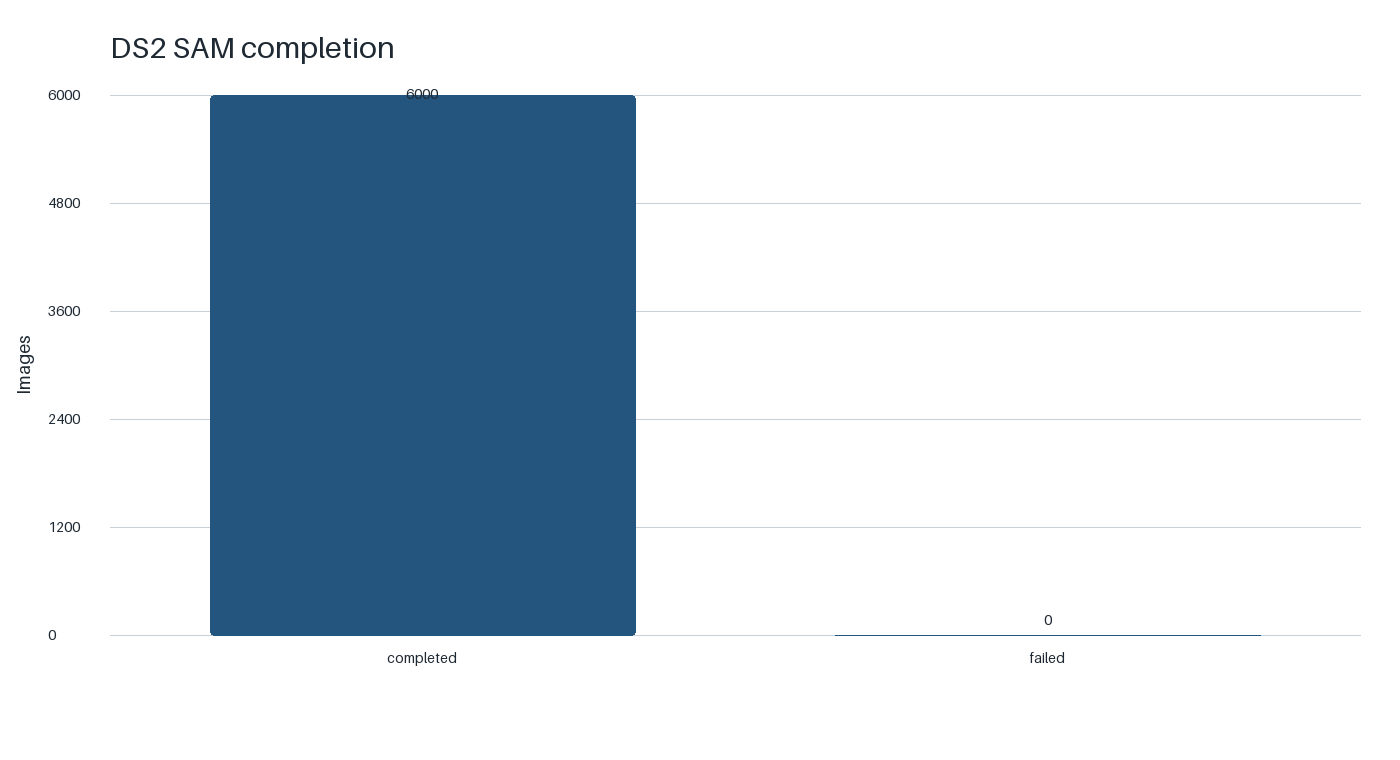

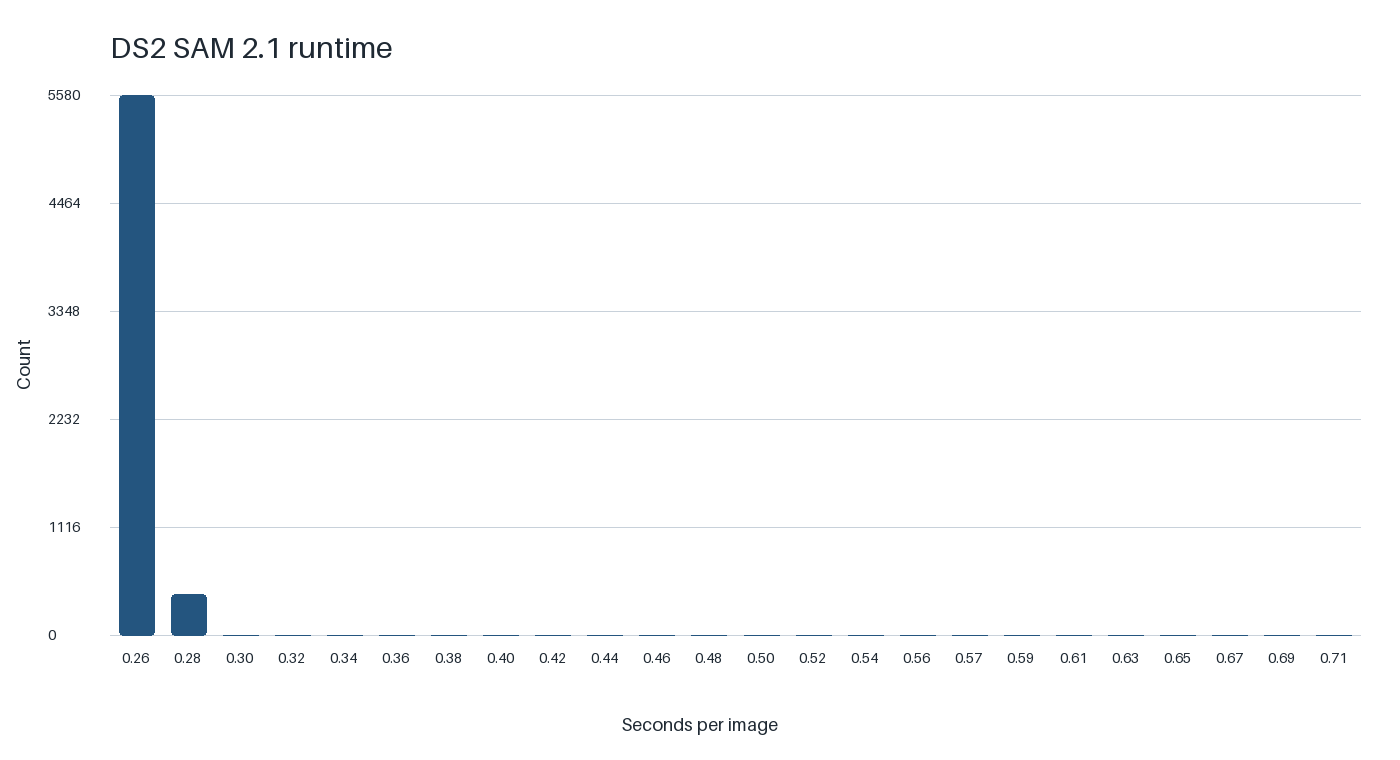

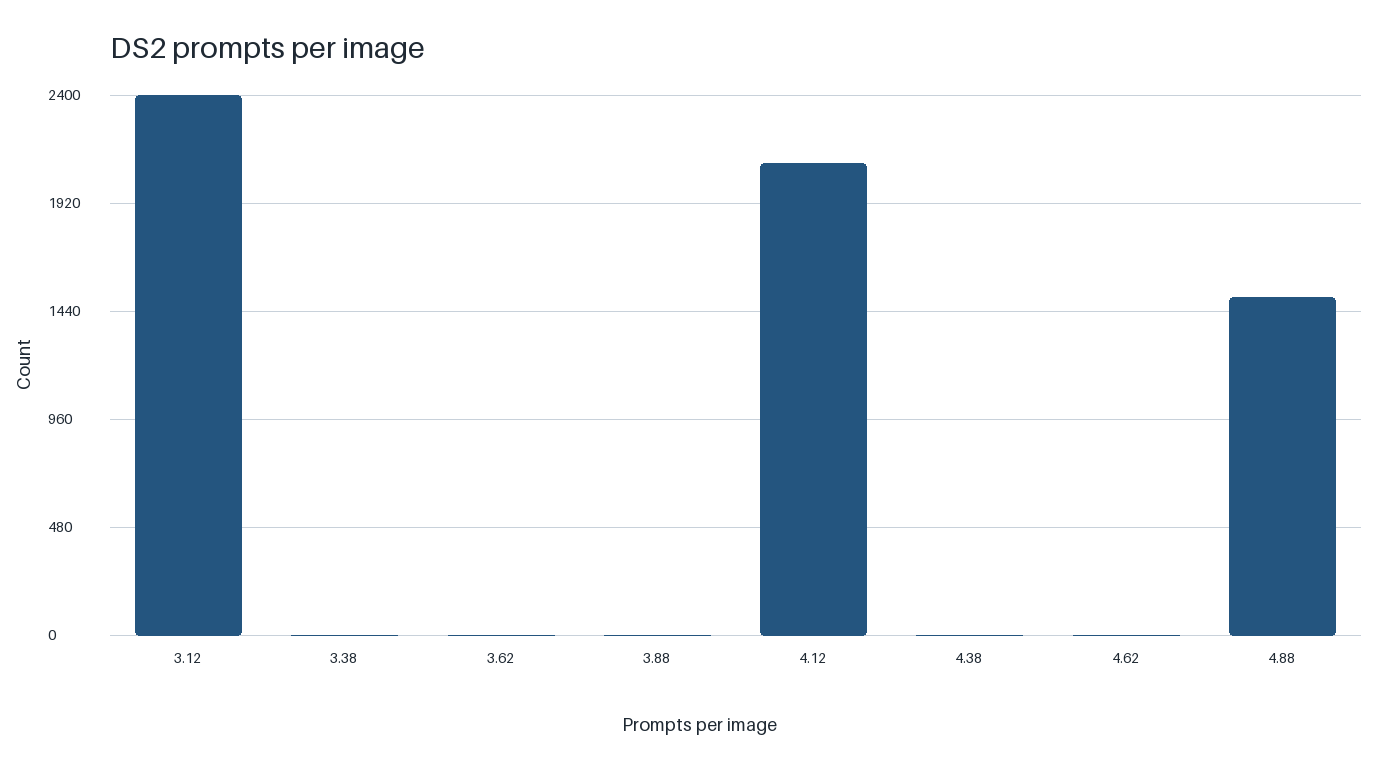

SAM route: automatic-box


,check,passed
0,all DS2 images recorded,True
1,stored prompts match the frozen input,True
2,pilot repeat completed and was measured,True
3,no unresolved SAM image failures,True


,route,image_count,mask_count,zero_prompt_image_count,empty_mask_count,mean_predicted_quality_score,median_runtime_seconds,p95_runtime_seconds,terminal_failed_image_count,genuine_zero_proposal_image_count,discarded_untrusted_box_count
0,automatic_box,6000,23180,38,1,0.976971,0.267283,0.274368,2,36,227


,mask_digest_agreement_rate,matching_mask_digest_count,matching_score_count,pilot_image_count,prompt_count,repeat_image_count,score_agreement_rate,score_tolerance
0,1.0,84,84,20,84,20,1.0,0.00001


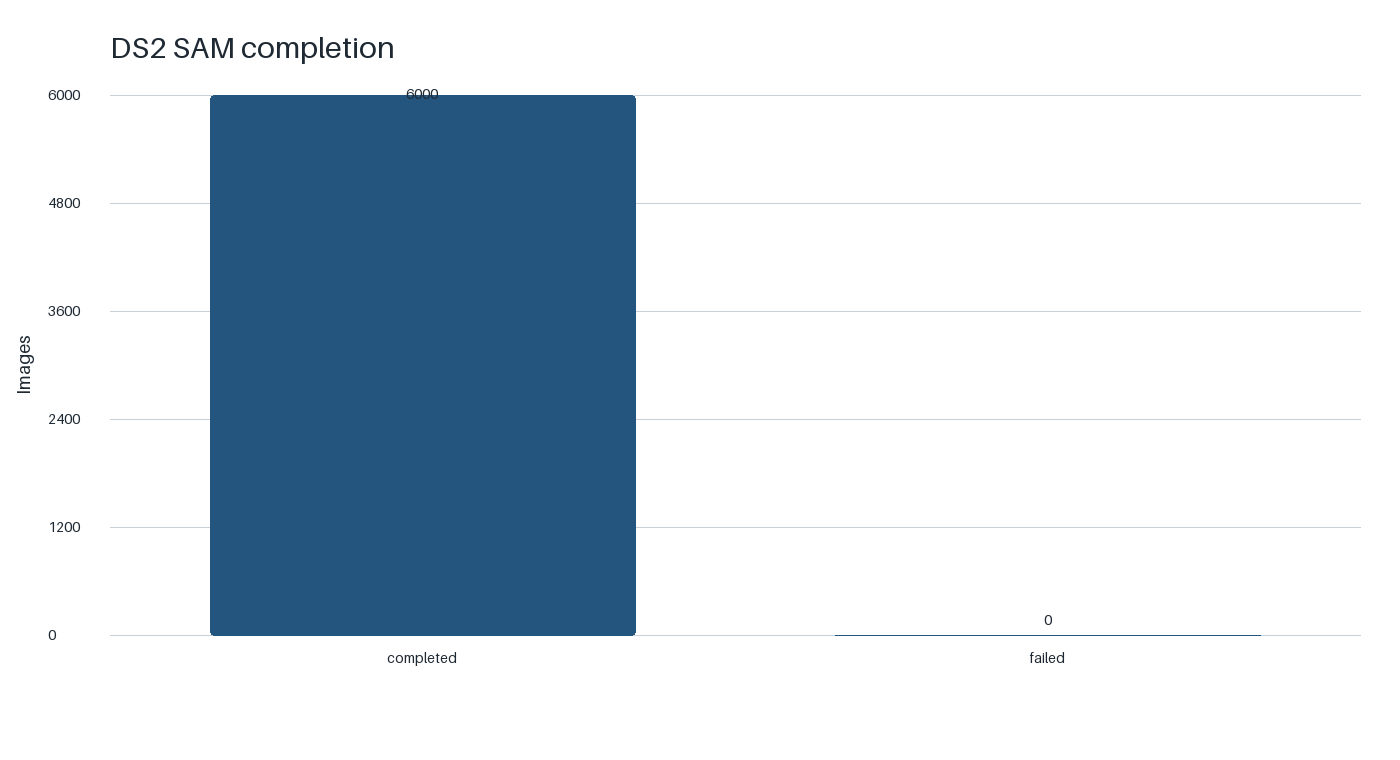

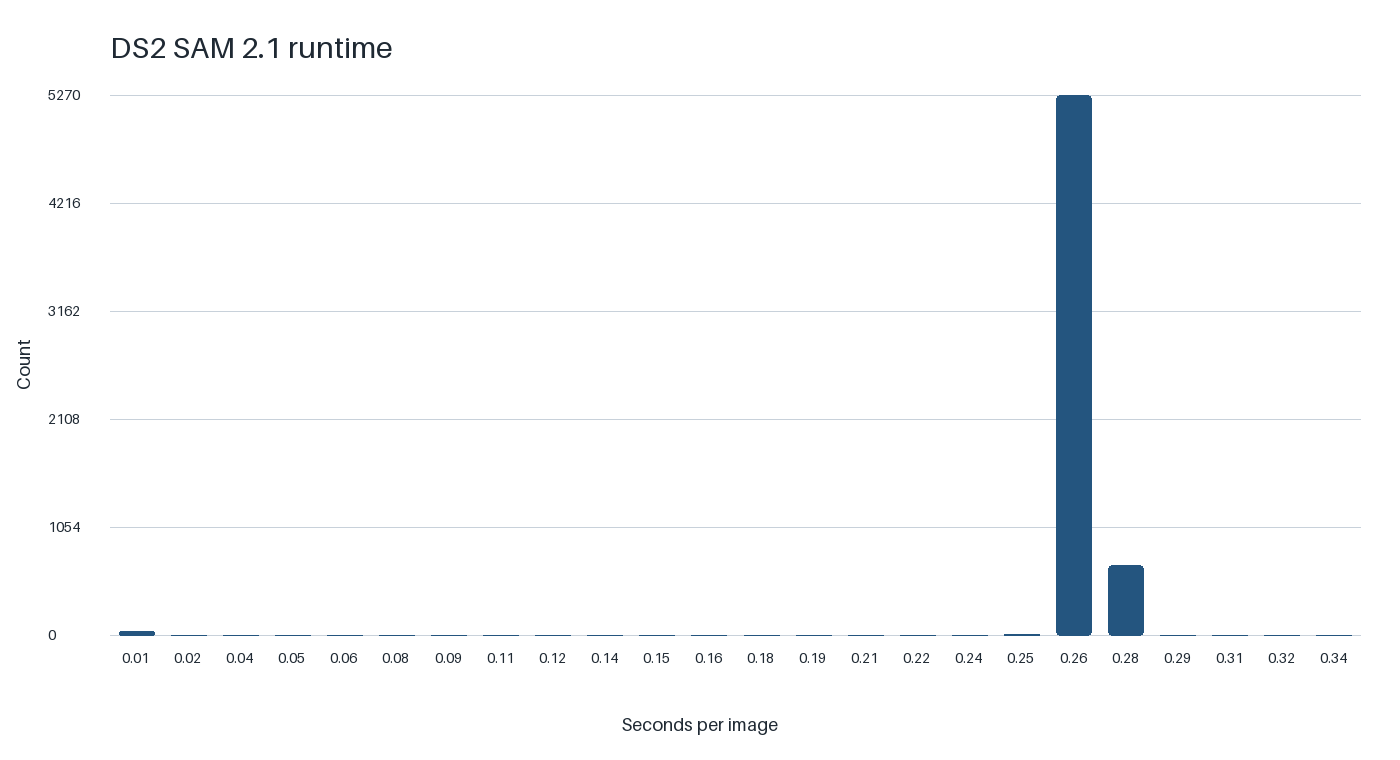

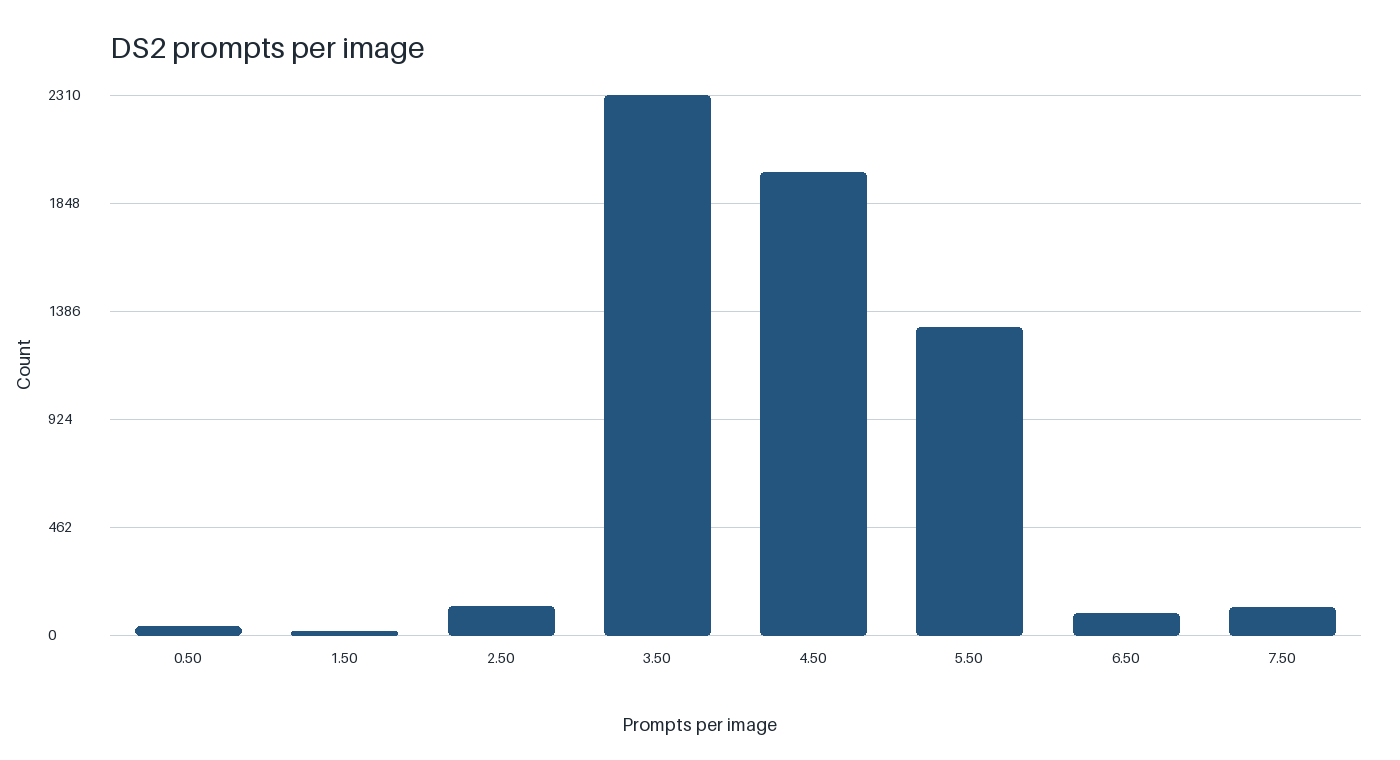

,gate,expected,observed,passed
0,scene_coverage,300,300,True
1,score_coverage,138760,138760,True
2,finite_scored_values,True,True,True
3,evaluator_closed,False,False,True


,stage,scene_count,candidate_count,encoded_candidate_count,invalid_mask_candidate_count,encoder_call_count,resumed_scene_count,runtime_seconds_this_session
0,dino_and_peer_scores,300,69380,69379,1,2314,0,717.272851


,route,candidate_count,scored_candidate_count,mean_p1_score,median_p1_score,p95_p1_score,unscoreable_candidate_count,invalid_mask_candidate_count
0,supplied_mask,23100,23100,0.429930,0.430538,0.601706,0,0
1,reference_box,23100,23100,0.439777,0.441660,0.613820,0,0
2,automatic_box,23180,22915,0.444847,0.446168,0.629337,265,1


,batch_size,crop_configuration,invalid_mask_policy,methods,model_key,model_specification,p1_top_fraction,patch_validity_minimum_fraction,resolved_revision,routes,run_mode,stage
0,32,"{'background_rgb': [238, 241, 245], 'input_siz...","{'ranking_evidence': 0.0, 'reason': 'foregroun...","[B0, P1]",dinov2_small,"{'backend': 'transformers_dino', 'family': 'DI...",0.1,0.5,ed25f3a31f01632728cabb09d1542f84ab7b0056,"[supplied_mask, reference_box, automatic_box]",model_inference,ds2_frozen_representation_and_peer_scores


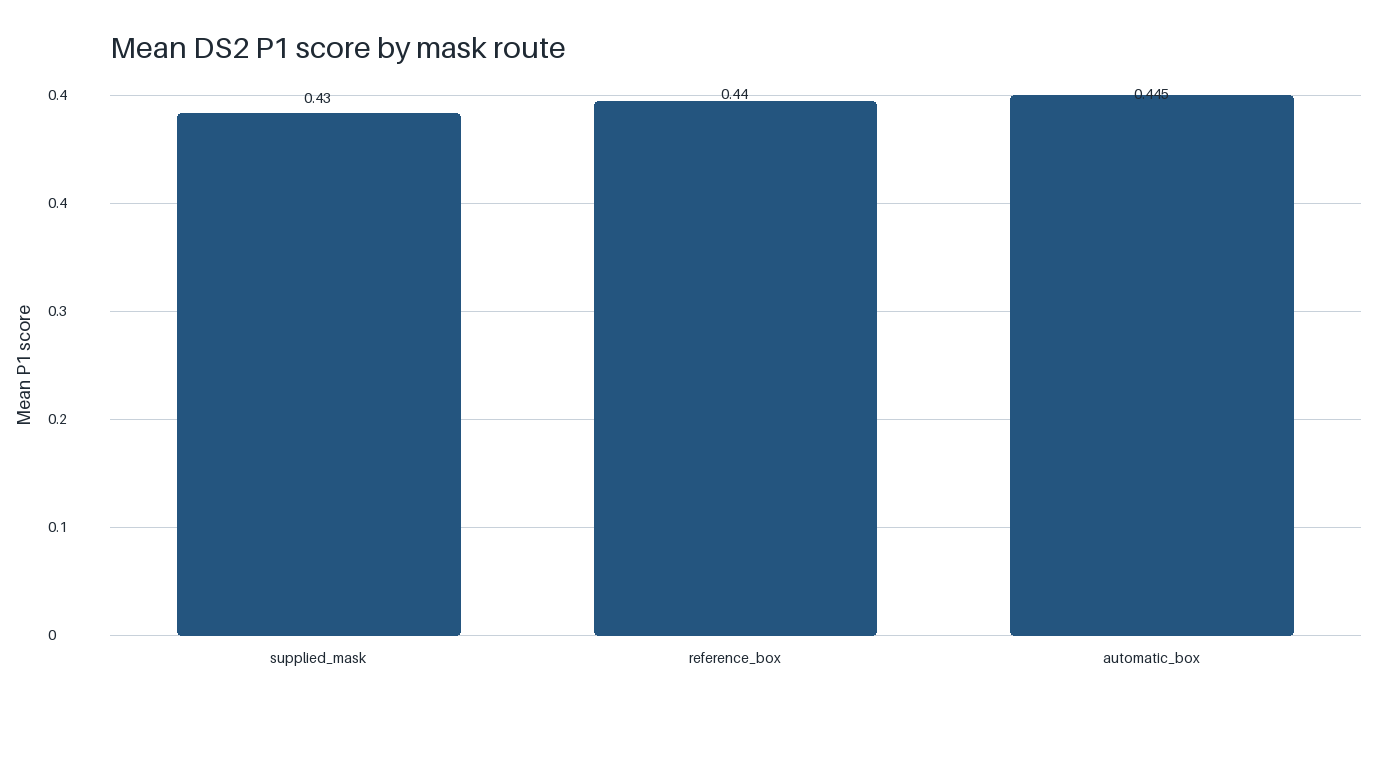

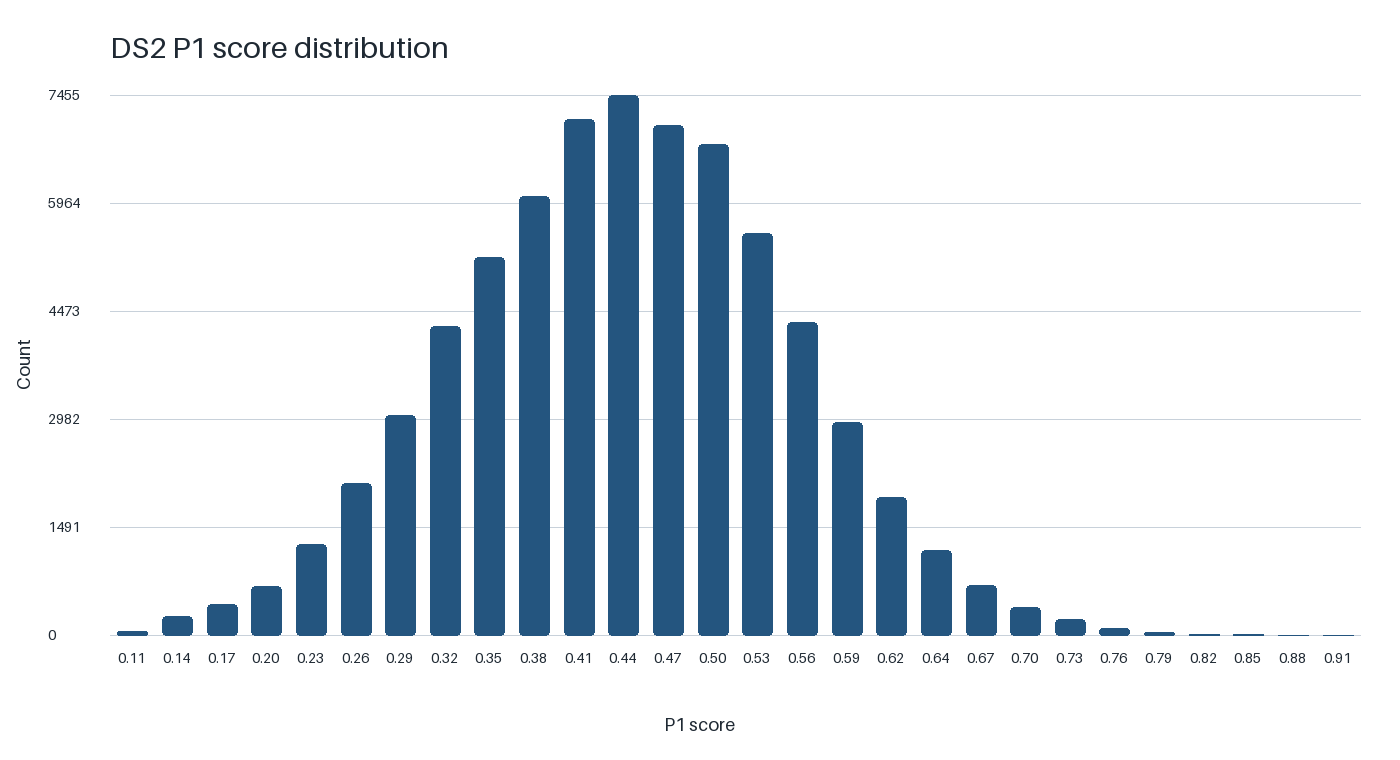

Every proposal remains in the score manifest. A mask with too little foreground is marked invalid_mask with no invented DINO score or rank.
B0 and P1 accuracy is reported only after Notebook 08C opens the protected evaluator.


In [6]:
import pandas as pd

proposal_safe = OUTPUT_ROOT / "locateanything/safe"
reference_sam_safe = OUTPUT_ROOT / "sam21/reference-box/safe"
automatic_sam_safe = OUTPUT_ROOT / "sam21/automatic-box/safe"
representation_safe = OUTPUT_ROOT / "representation/safe"
display(pd.read_csv(proposal_safe / "completion_checks.csv"))
display(pd.DataFrame([json.loads((proposal_safe / "operational_summary.json").read_text(encoding="utf-8"))]))
display(pd.DataFrame([json.loads((proposal_safe / "repeat_agreement.json").read_text(encoding="utf-8"))]))
display(NotebookImage(filename=str(proposal_safe / "completion_summary.png")))
display(NotebookImage(filename=str(proposal_safe / "proposal_count_distribution.png")))
display(NotebookImage(filename=str(proposal_safe / "runtime_distribution.png")))
for route_name, route_root in (
    ("reference-box", reference_sam_safe),
    ("automatic-box", automatic_sam_safe),
):
    print(f"SAM route: {route_name}")
    display(pd.read_csv(route_root / "completion_checks.csv"))
    display(pd.read_csv(route_root / "route_summary.csv"))
    display(pd.DataFrame([json.loads((route_root / "repeat_agreement.json").read_text(encoding="utf-8"))]))
    display(NotebookImage(filename=str(route_root / "completion_summary.png")))
    display(NotebookImage(filename=str(route_root / "runtime_distribution.png")))
    display(NotebookImage(filename=str(route_root / "prompt_count_distribution.png")))
display(pd.read_csv(representation_safe / "completion_gates.csv"))
display(pd.read_csv(representation_safe / "runtime_summary.csv"))
display(pd.read_csv(representation_safe / "p1_route_summary.csv"))
display(pd.DataFrame([json.loads((representation_safe / "resolved_configuration.json").read_text(encoding="utf-8"))]))
display(NotebookImage(filename=str(representation_safe / "mean_p1_by_route.png")))
display(NotebookImage(filename=str(representation_safe / "p1_score_distribution.png")))
print("Every proposal remains in the score manifest. A mask with too little foreground is marked invalid_mask with no invented DINO score or rank.")
print("B0 and P1 accuracy is reported only after Notebook 08C opens the protected evaluator.")

## Private qualitative checks

The proposal panel shows the fixed LocateAnything boxes on 20 varied confirmation images. The next two panels show SAM mask boundaries for the assisted and automatic routes. The final panel shows high P1 mismatch crops. Red heatmap regions indicate stronger feature mismatch and are not exact defect boundaries. These panels remain in private Kaggle output for review.

In [7]:
display(NotebookImage(filename=str(OUTPUT_ROOT / "locateanything/private/figures/proposal_examples.png")))
display(NotebookImage(filename=str(OUTPUT_ROOT / "sam21/reference-box/private/figures/reference_box_mask_examples.png")))
display(NotebookImage(filename=str(OUTPUT_ROOT / "sam21/automatic-box/private/figures/automatic_box_mask_examples.png")))
display(NotebookImage(filename=str(OUTPUT_ROOT / "representation/private/figures/p1_heatmap_examples.png")))

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

## Bounded ClearML finalisation

In [8]:
# Tracking runs after the model artifacts and manifests are complete.
if EXECUTION_ENVIRONMENT == "kaggle":
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_ROOT / "requirements/confirmation-tracking-lock.txt")], check=True, timeout=180)
    except Exception as error:
        print(f"ClearML dependency setup was unavailable: {type(error).__name__}")
proposal_tracking = run_clearml_finalizer(
    proposal_safe,
    "ds2_frozen_locateanything",
    "ds2-frozen-locateanything",
    ["notebook-08b", "ds2", "locateanything", "kaggle"],
    OUTPUT_ROOT / "locateanything/clearml_receipt.json",
)
reference_sam_tracking = run_clearml_finalizer(
    reference_sam_safe,
    "ds2_reference_box_sam21",
    "ds2-reference-box-sam21",
    ["notebook-08b", "ds2", "sam2.1", "kaggle"],
    OUTPUT_ROOT / "sam21/reference-box/clearml_receipt.json",
)
automatic_sam_tracking = run_clearml_finalizer(
    automatic_sam_safe,
    "ds2_automatic_box_sam21",
    "ds2-automatic-box-sam21",
    ["notebook-08b", "ds2", "sam2.1", "automatic-box", "kaggle"],
    OUTPUT_ROOT / "sam21/automatic-box/clearml_receipt.json",
)
representation_tracking = run_clearml_finalizer(
    representation_safe,
    "ds2_frozen_representation_and_peer_scores",
    "ds2-dinov2-small-p1",
    ["notebook-08b", "ds2", "dinov2-small", "p1", "kaggle"],
    OUTPUT_ROOT / "representation/clearml_receipt.json",
)
display({
    "LocateAnything tracking": proposal_tracking,
    "reference-box SAM tracking": reference_sam_tracking,
    "automatic-box SAM tracking": automatic_sam_tracking,
    "representation tracking": representation_tracking,
})

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.1 MB/s eta 0:00:00


{'LocateAnything tracking': {'mode': 'disabled',
  'run_status': 'completed',
  'safe_manifest_sha256': '81db9a38ddddc6f0d46aeb5a16e9a56a2671c1dbb825a889e726738f278072b6',
  'schema_version': 1,
  'stage': 'ds2_frozen_locateanything_clearml_finalisation',
  'status': 'disabled',
  'task_id': None,
  'tracking_attempt_count': 0,
  'tracking_retry_count': 0,
  'tracking_transient_failure_count': 0},
 'reference-box SAM tracking': {'mode': 'disabled',
  'run_status': 'completed',
  'safe_manifest_sha256': '94344ee44ace22e16bdb6b1bd752761f09596e4a5d411bfd0ee10ace37f6a34f',
  'schema_version': 1,
  'stage': 'ds2_reference_box_sam21_clearml_finalisation',
  'status': 'disabled',
  'task_id': None,
  'tracking_attempt_count': 0,
  'tracking_retry_count': 0,
  'tracking_transient_failure_count': 0},
 'automatic-box SAM tracking': {'mode': 'disabled',
  'run_status': 'completed',
  'safe_manifest_sha256': 'd12c235ff14c304b20b0c24a9fe0b911a029b2d908ad95778884da6e0f9635d0',
  'schema_version': 1,

## Build compact verified downloads

Expanded checkpoints and feature caches stay in temporary Kaggle storage. The following archives retain aggregate GitHub evidence, selected private review panels, and the three files required by the protected evaluator. Each archive is checksum verified before the notebook finishes.

In [9]:
BUNDLE_ROOT = (
    Path("/kaggle/working/notebook08b_bundles")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else OUTPUT_ROOT.parent / "notebook08b_bundles"
)
bundle_specs = [
    (OUTPUT_ROOT / "locateanything", "ds2-locateanything", ["private/figures", "clearml_receipt.json"], []),
    (OUTPUT_ROOT / "sam21/reference-box", "ds2-reference-sam21", ["private/figures", "clearml_receipt.json"], ["private/sam_results.jsonl"]),
    (OUTPUT_ROOT / "sam21/automatic-box", "ds2-automatic-sam21", ["private/figures", "clearml_receipt.json"], ["private/sam_results.jsonl"]),
    (OUTPUT_ROOT / "representation", "ds2-dinov2-p1", ["private/figures", "clearml_receipt.json"], ["model-input"]),
]
bundle_rows = []
for stage_root, stage_name, review_paths, downstream_paths in bundle_specs:
    stage_bundle_root = BUNDLE_ROOT / stage_name
    verification_path = stage_bundle_root / f"{stage_name}-verification.json"
    if not verification_path.is_file():
        # Package review-only panels and downstream evaluator inputs separately.
        command = [
            sys.executable,
            str(CODE_ROOT / "scripts/package_kaggle_stage_output.py"),
            "--stage-root", str(stage_root),
            "--output-root", str(stage_bundle_root),
            "--stage-name", stage_name,
        ]
        for value in review_paths:
            command.extend(("--review-path", value))
        for value in downstream_paths:
            command.extend(("--downstream-path", value))
        subprocess.run(command, check=True, env=code_environment())
    record = json.loads(verification_path.read_text(encoding="utf-8"))
    for archive in record["archives"]:
        bundle_rows.append({"stage": stage_name, **archive})
display(pd.DataFrame(bundle_rows))
print(f"Verified downloads: {BUNDLE_ROOT}")
if RECOVERY_OUTPUT_ROOT.exists():
    shutil.rmtree(RECOVERY_OUTPUT_ROOT)
print("Temporary recovery checkpoints removed after verified bundle creation")

{"archives": [{"path": "ds2-locateanything-repository-evidence.zip", "sha256": "bb5f3793f38d0231d7812d33b9ec6fcd9ce8539c2dea50d4ae7e54515ca80d09", "size_bytes": 59997, "source_file_count": 8}, {"path": "ds2-locateanything-review-evidence.zip", "sha256": "68852cb455c878984dd1fa4f91bb56730164dbdf5469ff9067614e921913c25e", "size_bytes": 1232701, "source_file_count": 2}], "downstream_file_count": 0, "review_file_count": 2, "safe_file_count": 8, "safe_manifest_sha256": "81db9a38ddddc6f0d46aeb5a16e9a56a2671c1dbb825a889e726738f278072b6", "schema_version": 1, "stage": "ds2-locateanything", "status": "completed"}
{"archives": [{"path": "ds2-reference-sam21-repository-evidence.zip", "sha256": "940b2066f9533b0b522f8fdfa1c566a1d216f015fbd9e1305f733595e6a7fce8", "size_bytes": 48381, "source_file_count": 9}, {"path": "ds2-reference-sam21-review-evidence.zip", "sha256": "0b558a65b69acddb9a536c8ceddcf63b5d543fefc5492c8b27d2b8a0e6f7e1ab", "size_bytes": 664887, "source_file_count": 2}, {"path": "ds2-ref

,stage,path,sha256,size_bytes,source_file_count
0,ds2-locateanything,ds2-locateanything-repository-evidence.zip,bb5f3793f38d0231d7812d33b9ec6fcd9ce8539c2dea50...,59997,8
1,ds2-locateanything,ds2-locateanything-review-evidence.zip,68852cb455c878984dd1fa4f91bb56730164dbdf5469ff...,1232701,2
2,ds2-reference-sam21,ds2-reference-sam21-repository-evidence.zip,940b2066f9533b0b522f8fdfa1c566a1d216f015fbd9e1...,48381,9
3,ds2-reference-sam21,ds2-reference-sam21-review-evidence.zip,0b558a65b69acddb9a536c8ceddcf63b5d543fefc5492c...,664887,2
4,ds2-reference-sam21,ds2-reference-sam21-downstream-input.zip,2a9b8b0c562da8ddbc170fe2d7217b6168f5915ee95b3a...,5349047,1
5,ds2-automatic-sam21,ds2-automatic-sam21-repository-evidence.zip,71f15e20fae96fb34987107b9ebe79eb205426ecc600ea...,49713,9
6,ds2-automatic-sam21,ds2-automatic-sam21-review-evidence.zip,063c2239cf1f8d8f822722807cab4fd854ba1ea2bfa859...,664896,2
7,ds2-automatic-sam21,ds2-automatic-sam21-downstream-input.zip,36a1f534cfbbc4786c7dd1a7c7ae6905db89d2a5f7e6db...,5701830,1
8,ds2-dinov2-p1,ds2-dinov2-p1-repository-evidence.zip,f5adccb0496d6e1f83df56b21760548cc395b408263cd5...,38365,8
9,ds2-dinov2-p1,ds2-dinov2-p1-review-evidence.zip,b6b7091b847d75cbcd74eda8ca5120f20c6e237b29b03b...,69817,2


Verified downloads: /kaggle/working/notebook08b_bundles
Temporary recovery checkpoints removed after verified bundle creation


## Handoff to the evaluator

Notebook 08C consumes the reference SAM, automatic SAM, and DINO downstream archives from this completed version. The automatic SAM archive preserves the per-image proposal status and discarded-box count, so terminal model errors remain distinct from genuine zero-proposal outcomes. The evaluator must verify package hashes before opening protected attributes. It must not change a model, crop, prompt, post-processing rule, or score setting.